# 🚕 Predicción de duración de viajes de taxi en Nueva York

**Sistemas Inteligentes · FES Acatlán, UNAM**  
**Proyecto: regresión supervisada con evaluación ciega**  
**Archivos:** `train.csv` (700,000 filas) y `test.csv` (100,000 filas).

## Objetivo y entregables
Predecir `trip_duration` **en segundos**, por cada `id` de `test.csv`; generar `submission.csv` con dos columnas exactas y una fila por viaje. Buscar **el menor RMSLE de validación**, comprobar generalización con un holdout no utilizado para seleccionar modelos y volver a ajustar el modelo final con todos los datos utilizables.

El trabajo sigue las etapas **CRISP-DM** explicadas en *03 - Ciclo de vida del ML.pdf* (págs. 2–5): entendimiento del problema, exploración, preparación, modelado, evaluación y entrega. La distinción **regresión vs. clasificación** procede de *U5 - 01 - ML.pdf* (pág. 7); la normalización/estandarización, imputación y fuga de información se documentan en *03 - Ciclo de vida del ML.pdf* (págs. 9–15); y el uso de regresión lineal como línea base se relaciona con *U5 - 02 - Perceptrón.pdf* (págs. 3–7).

> **Importante:** F1, accuracy, recall y precision *no se definen directamente* para predecir una duración continua. Estas métricas son de **clasificación** (ver *03 - Ciclo de vida del ML.pdf*, págs. 21–24). Aquí el concurso evalúa **RMSLE**, por lo que añadiremos MAE, RMSE, MAPE y R² como medidas complementarias. No inventaremos etiquetas ni métricas artificiales para aparentar un resultado mejor.

## 0. Librerías, semilla y reproducibilidad
Las rutas son relativas al notebook. La **semilla fija** permite reproducir la partición y la selección de hiperparámetros; los resultados exactos pueden variar ligeramente según la versión de las librerías o el hardware.

In [1]:
from pathlib import Path
import os, json, math, warnings, time, sys, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn, lightgbm, xgboost, catboost
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import Ridge
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_squared_log_error, r2_score
from lightgbm import LGBMRegressor, early_stopping, log_evaluation
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
warnings.filterwarnings('ignore', category=FutureWarning)
SEED = 42
np.random.seed(SEED)
ROOT = Path.cwd()
ARTIFACTS = ROOT / 'resultados'
GRAPHS = ARTIFACTS / 'graficos'
MODELS = ROOT / 'modelos'
for folder in [ARTIFACTS, GRAPHS, MODELS]: folder.mkdir(parents=True, exist_ok=True)
TRAIN_PATH, TEST_PATH = ROOT / 'train.csv', ROOT / 'test.csv'
assert TRAIN_PATH.exists() and TEST_PATH.exists(), 'Coloca train.csv y test.csv junto al notebook.'
print('Python:', sys.version.split()[0], '| pandas:', pd.__version__, '| sklearn:', sklearn.__version__, '| LightGBM:', lightgbm.__version__)
print('Directorio de trabajo:', ROOT)

Python: 3.13.5 | pandas: 2.2.3 | sklearn: 1.8.0 | LightGBM: 4.6.0
Directorio de trabajo: /mnt/data


## 1. Comprensión del negocio y de la métrica
**Tipo:** aprendizaje supervisado de regresión. `trip_duration` está disponible únicamente en entrenamiento. 

$$\mathrm{RMSLE} = \sqrt{\frac{1}{n}\sum_{i=1}^{n}\left[\ln(1+\hat y_i)-\ln(1+y_i)\right]^2}.$$

RMSLE trata de manera parecida los errores multiplicativos: equivocarse de 200 a 400 s es comparable a equivocarse de 600 a 1200 s (aproximadamente). Para entrenar modelos en la escala de la evaluación, usamos `z = log1p(trip_duration)` y recuperamos segundos con `expm1(z)`. Esta transformación de la **variable objetivo** no es lo mismo que estandarizar las variables predictoras. Predicciones siempre truncadas a cero.

In [2]:
def rmsle(y_true, y_pred):
    t=np.asarray(y_true, dtype=np.float64)
    p=np.maximum(np.asarray(y_pred, dtype=np.float64), 0.0)
    return float(np.sqrt(mean_squared_log_error(t,p)))

def regression_metrics(y_true, y_pred):
    a=np.asarray(y_true, dtype=np.float64)
    b=np.maximum(np.asarray(y_pred, dtype=np.float64),0)
    return {'RMSLE':rmsle(a,b), 'MAE_segundos':float(mean_absolute_error(a,b)),
            'RMSE_segundos':float(np.sqrt(mean_squared_error(a,b))),
            'R2':float(r2_score(a,b)),
            'MAPE_%':float(np.mean(np.abs((a-b)/np.maximum(np.abs(a), 1.0)))*100)}

def seconds_from_log(y_log):
    return np.expm1(np.clip(np.asarray(y_log, dtype=np.float64),0,20))
print('RMSLE de ejemplo:',rmsle([100,200],[110,190]))

RMSLE de ejemplo: 0.0758861004209218


## 2. Carga y auditoría inicial de calidad
Revisamos tipos, cantidad de filas, categorías, duplicados, nulos y estadísticas del objetivo. **No descartamos filas de `test.csv`**, pues las 100,000 deben recibir predicción. Preservamos el orden original de los identificadores.

In [3]:
train = pd.read_csv(TRAIN_PATH, parse_dates=['pickup_datetime'])
test = pd.read_csv(TEST_PATH, parse_dates=['pickup_datetime'])
assert list(train.columns) == list(test.columns)+['trip_duration'], 'Revisar esquema de columnas.'
assert len(train)==700_000 and len(test)==100_000
assert test['id'].is_unique and train['id'].is_unique
assert 'trip_duration' not in test.columns
original_test_ids = test['id'].copy()
print('Entrenamiento:',train.shape,'| Evaluación ciega:',test.shape)
display(train.head(5))
display(pd.DataFrame({'tipo_train':train.dtypes.astype(str), 'nulos_train':train.isna().sum(), 'nulos_test':test.reindex(columns=train.columns).isna().sum()}).fillna(0))
print('Tipos de empresa:',train.vendor_id.value_counts().to_dict())
print('Bandera de conexión:',train.store_and_fwd_flag.value_counts().to_dict())
print('Fechas de inicio:',train.pickup_datetime.min(),'a',train.pickup_datetime.max())

Entrenamiento: (700000, 10) | Evaluación ciega: (100000, 9)


,id,vendor_id,pickup_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration
0,58e21c919561473fa50f492e85f48eb5,1,2016-04-07 21:14:34,1,-73.978127,40.751179,-73.963081,40.711830,N,1320
1,542584aec3304a9d8d187bd916a6b271,2,2016-04-30 23:26:34,1,-73.992531,40.730431,-74.007011,40.734951,N,588
2,e0e1e91b49dd4c8dac7db5da5a6b28e4,1,2016-06-21 15:19:46,1,-73.973366,40.763535,-73.978844,40.761982,N,353
3,fb21862ebf1f4fbf8ee3f1ca28960b95,1,2016-01-04 13:05:36,2,-73.870987,40.773769,-73.988350,40.756027,N,1576
4,28f619a7898c47289613bbf493be8606,1,2016-04-21 21:26:43,1,-73.972557,40.762337,-73.955597,40.773682,N,345


,tipo_train,nulos_train,nulos_test
id,object,0,0
vendor_id,int64,0,0
pickup_datetime,datetime64[ns],0,0
passenger_count,int64,0,0
pickup_longitude,float64,0,0
pickup_latitude,float64,0,0
dropoff_longitude,float64,0,0
dropoff_latitude,float64,0,0
store_and_fwd_flag,object,0,0
trip_duration,int64,0,100000


Tipos de empresa: {2: 374330, 1: 325670}
Bandera de conexión: {'N': 696125, 'Y': 3875}
Fechas de inicio: 2016-01-01 00:00:17 a 2016-06-30 23:59:39


### 2.1. Detección de atípicos y registros inconsistentes
Separamos **análisis**, **selección de registros para ajustar modelos** y **evaluación**. Esto evita presentar una métrica artificialmente buena: los registros extremos **sí permanecen** en validación y holdout. Para el ajuste, el filtro de duraciones mayores que 12 h afecta solamente al subconjunto de entrenamiento y se justifica como mitigación del ruido extremo. Las coordenadas fuera de una caja geográfica razonable se imputan posteriormente (con los valores de entrenamiento únicamente).

In [4]:
geo_cols=['pickup_longitude','pickup_latitude','dropoff_longitude','dropoff_latitude']
quality={
 'train_filas':int(len(train)), 'test_filas':int(len(test)),
 'nulos_train':{k:int(v) for k,v in train.isna().sum().items()},
 'nulos_test':{k:int(v) for k,v in test.isna().sum().items()},
 'id_duplicado_train':int(train.id.duplicated().sum()),
 'id_duplicado_test':int(test.id.duplicated().sum()),
 'duracion_menor_igual_cero':int((train.trip_duration<=0).sum()),
 'duracion_mayor_12h':int((train.trip_duration>43200).sum()),
 'duracion_mayor_24h':int((train.trip_duration>86400).sum()),
 'pasajeros_cero_train':int((train.passenger_count==0).sum()),
 'origen_fuera_zona_NYC':int((~train.pickup_longitude.between(-74.5,-73.3) | ~train.pickup_latitude.between(40.4,41.2)).sum()),
 'destino_fuera_zona_NYC':int((~train.dropoff_longitude.between(-74.5,-73.3) | ~train.dropoff_latitude.between(40.4,41.2)).sum()),
}
print(json.dumps(quality,indent=2,ensure_ascii=False))
print('Resumen objetivo en segundos:')
display(train.trip_duration.describe(percentiles=[.01,.05,.25,.50,.75,.95,.99,.999]).to_frame())
(ARTIFACTS/'auditoria_calidad.json').write_text(json.dumps(quality,ensure_ascii=False,indent=2),encoding='utf-8')

{
  "train_filas": 700000,
  "test_filas": 100000,
  "nulos_train": {
    "id": 0,
    "vendor_id": 0,
    "pickup_datetime": 0,
    "passenger_count": 0,
    "pickup_longitude": 0,
    "pickup_latitude": 0,
    "dropoff_longitude": 0,
    "dropoff_latitude": 0,
    "store_and_fwd_flag": 0,
    "trip_duration": 0
  },
  "nulos_test": {
    "id": 0,
    "vendor_id": 0,
    "pickup_datetime": 0,
    "passenger_count": 0,
    "pickup_longitude": 0,
    "pickup_latitude": 0,
    "dropoff_longitude": 0,
    "dropoff_latitude": 0,
    "store_and_fwd_flag": 0
  },
  "id_duplicado_train": 0,
  "id_duplicado_test": 0,
  "duracion_menor_igual_cero": 0,
  "duracion_mayor_12h": 984,
  "duracion_mayor_24h": 2,
  "pasajeros_cero_train": 24,
  "origen_fuera_zona_NYC": 32,
  "destino_fuera_zona_NYC": 54
}
Resumen objetivo en segundos:


,trip_duration
count,7.000000e+05
mean,9.641360e+02
std,5.927138e+03
min,1.000000e+00
1%,8.600000e+01
5%,1.800000e+02
25%,3.970000e+02
50%,6.620000e+02
75%,1.076000e+03
95%,2.106000e+03


800

### 2.2. Exploración gráfica
Se visualiza `log1p(trip_duration)` porque una cola larga de viajes extremos oculta la distribución principal. También la demanda horaria y la distribución espacial inicial.

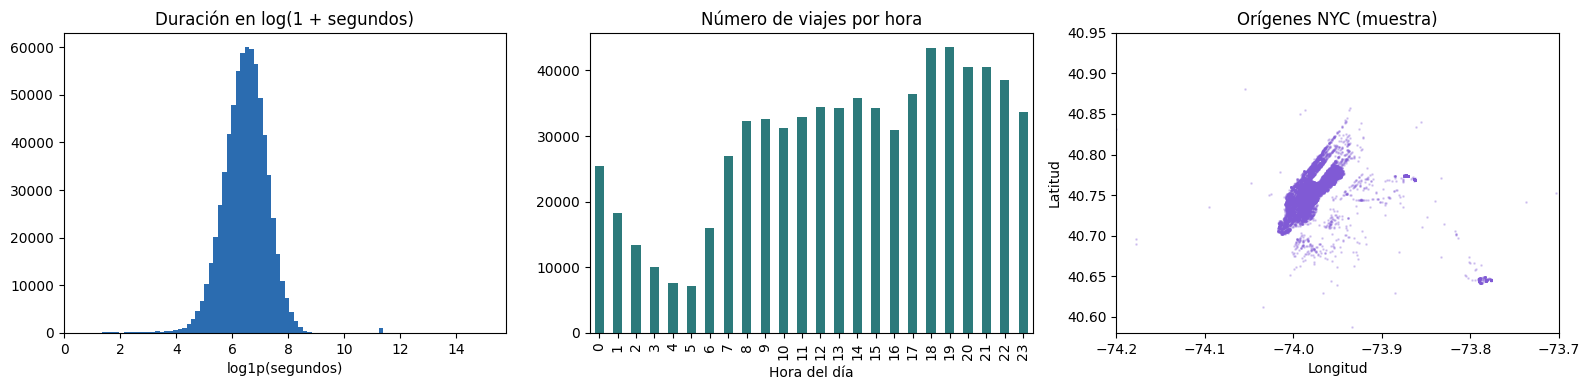

In [5]:
fig,axs=plt.subplots(1,3,figsize=(16,4))
axs[0].hist(np.log1p(train.trip_duration),bins=90,color='#2b6cb0'); axs[0].set_title('Duración en log(1 + segundos)'); axs[0].set_xlabel('log1p(segundos)')
train.pickup_datetime.dt.hour.value_counts().sort_index().plot(kind='bar',ax=axs[1],color='#2c7a7b'); axs[1].set_title('Número de viajes por hora'); axs[1].set_xlabel('Hora del día')
sample=train.sample(12_000,random_state=SEED)
axs[2].scatter(sample.pickup_longitude,sample.pickup_latitude,s=0.9,alpha=.23,color='#805ad5'); axs[2].set_xlim(-74.2,-73.7); axs[2].set_ylim(40.58,40.95); axs[2].set_title('Orígenes NYC (muestra)'); axs[2].set_xlabel('Longitud'); axs[2].set_ylabel('Latitud')
plt.tight_layout(); plt.savefig(GRAPHS/'01_exploracion.png',dpi=145,bbox_inches='tight'); plt.show()

## 3. Partición ANTES de ajustar el preprocesamiento
Separamos aleatoriamente **80 % entrenamiento, 10 % validación, 10 % holdout final**; todos los viajes del CSV ciego permanecen aparte. El holdout no interviene en selección de variables, parámetros, early stopping ni blend. Se evalúa **una sola vez** tras seleccionar modelo con validación. Aplicamos el mismo transformador, ajustado solo sobre el subconjunto de entrenamiento, a las demás particiones. No entrenamos con `id` (identificador sin significado causal).

In [6]:
indices=np.arange(len(train))
idx_train,idx_temp=train_test_split(indices,test_size=.20,random_state=SEED)
idx_valid,idx_holdout=train_test_split(idx_temp,test_size=.50,random_state=SEED)
tr=train.iloc[idx_train].copy(); va=train.iloc[idx_valid].copy(); ho=train.iloc[idx_holdout].copy()
TARGET='trip_duration'
MAX_TRAIN_TARGET=43_200
tr_fit=tr.loc[tr[TARGET].between(1,MAX_TRAIN_TARGET)].copy()
print('Ajuste:',len(tr_fit),'| validación:',len(va),'| holdout:',len(ho))
print('Excluidos SOLO del ajuste (duración > 12h):',len(tr)-len(tr_fit))
print('No se usará el holdout hasta acabar la selección.')

Ajuste: 559212 | validación: 70000 | holdout: 70000
Excluidos SOLO del ajuste (duración > 12h): 788
No se usará el holdout hasta acabar la selección.


## 4. Limpieza y FEATURE ENGINEERING (variables nuevas)
Variables de utilidad física y urbana, siempre calculables **antes de conocer la duración**:

- **Tiempo:** hora, minuto, día de la semana, mes, día del año, fin de semana, hora punta, seno y coseno para ciclos de 24 h y 7 días.
- **Geometría:** distancia aérea Haversine, distancia aproximada Manhattan, desplazamientos este-oeste/norte-sur, ángulo y dirección de la trayectoria.
- **Ubicación:** latitud/longitud, punto medio, celdas geográficas y distancias a JFK, LaGuardia, Newark, Times Square, Grand Central.
- **Calidad:** anomalías GPS, pasajeros inválidos y conexión diferida.

**No usamos `trip_duration`, una hora de llegada no proporcionada ni una velocidad calculada a partir de la duración real** para generar atributos. Evitamos fuga de información.

In [7]:
def haversine_np(lat1, lon1, lat2, lon2):
    """Distancia ortodrómica en km, con NumPy vectorizado."""
    lat1,lon1,lat2,lon2=map(np.radians,(lat1,lon1,lat2,lon2))
    dl=lat2-lat1; dn=lon2-lon1
    a=np.sin(dl/2)**2+np.cos(lat1)*np.cos(lat2)*np.sin(dn/2)**2
    return 6371.0088*2*np.arcsin(np.sqrt(np.clip(a,0,1)))

def create_features(frame):
    d=frame.copy()
    out=pd.DataFrame(index=d.index)
    dt=pd.to_datetime(d['pickup_datetime'],errors='coerce')
    hour=dt.dt.hour+dt.dt.minute/60+dt.dt.second/3600
    wd=dt.dt.dayofweek
    out['vendor_id']=pd.to_numeric(d.vendor_id,errors='coerce')
    out['passenger_count']=pd.to_numeric(d.passenger_count,errors='coerce')
    out['passenger_invalid']=(out.passenger_count<1).astype('int8')
    out['store_and_fwd_flag']=(d.store_and_fwd_flag=='Y').astype('int8')
    out['month']=dt.dt.month
    out['day']=dt.dt.day
    out['day_of_year']=dt.dt.dayofyear
    out['day_of_week']=wd
    out['week_of_year']=dt.dt.isocalendar().week.astype('float64')
    out['hour']=dt.dt.hour
    out['hour_decimal']=hour
    out['minute']=dt.dt.minute
    out['is_weekend']=wd.isin([5,6]).astype('int8')
    out['is_rush_hour']=((wd<5)&(((hour>=7)&(hour<10))|((hour>=16)&(hour<20)))).astype('int8')
    out['is_night']=((hour<6)|(hour>=22)).astype('int8')
    out['hour_sin']=np.sin(2*np.pi*hour/24)
    out['hour_cos']=np.cos(2*np.pi*hour/24)
    out['weekday_sin']=np.sin(2*np.pi*wd/7)
    out['weekday_cos']=np.cos(2*np.pi*wd/7)
    out['dayyear_sin']=np.sin(2*np.pi*dt.dt.dayofyear/366)
    out['dayyear_cos']=np.cos(2*np.pi*dt.dt.dayofyear/366)
    out['month_sin']=np.sin(2*np.pi*(dt.dt.month-1)/12)
    out['month_cos']=np.cos(2*np.pi*(dt.dt.month-1)/12)
    for c in ['pickup_longitude','pickup_latitude','dropoff_longitude','dropoff_latitude']:
        out[c]=pd.to_numeric(d[c],errors='coerce')
    for prefix in ['pickup','dropoff']:
        lon=out[f'{prefix}_longitude']; lat=out[f'{prefix}_latitude']
        bad=(~lon.between(-74.5,-73.3))|(~lat.between(40.4,41.2))
        out[f'{prefix}_bad_gps']=bad.astype('int8')
        out.loc[bad,[f'{prefix}_longitude',f'{prefix}_latitude']]=np.nan
    lon1=out.pickup_longitude.to_numpy(); lon2=out.dropoff_longitude.to_numpy()
    lat1=out.pickup_latitude.to_numpy(); lat2=out.dropoff_latitude.to_numpy()
    latm=(lat1+lat2)/2
    dy=(lat2-lat1)*111.195
    dx=(lon2-lon1)*111.195*np.cos(np.radians(latm))
    out['dx_km']=dx; out['dy_km']=dy
    out['abs_dx_km']=np.abs(dx);out['abs_dy_km']=np.abs(dy)
    out['haversine_km']=haversine_np(lat1,lon1,lat2,lon2)
    out['manhattan_km']=np.abs(dx)+np.abs(dy)
    out['haversine_log']=np.log1p(out['haversine_km'])
    out['manhattan_log']=np.log1p(out['manhattan_km'])
    out['trip_distance_squared']=out.haversine_km**2
    out['manhattan_ratio']=out.manhattan_km/(out.haversine_km+0.1)
    out['is_near_zero_distance']=(out.haversine_km<0.10).astype('int8')
    out['bearing']=np.arctan2(dx,dy)
    out['bearing_sin']=np.sin(out.bearing)
    out['bearing_cos']=np.cos(out.bearing)
    out['mid_lat']=(lat1+lat2)/2
    out['mid_lon']=(lon1+lon2)/2
    out['lat_lon_start_prod']=lat1*lon1
    out['lat_lon_end_prod']=lat2*lon2
    for prefix in ['pickup','dropoff']:
        lon=out[f'{prefix}_longitude'];lat=out[f'{prefix}_latitude']
        out[f'{prefix}_grid_lat_100']=(lat*100).round()
        out[f'{prefix}_grid_lon_100']=(lon*100).round()
        out[f'{prefix}_grid_lat_200']=(lat*200).round()
        out[f'{prefix}_grid_lon_200']=(lon*200).round()
        out[f'{prefix}_grid_lat_500']=(lat*500).round()
        out[f'{prefix}_grid_lon_500']=(lon*500).round()
        # Las ubicaciones son geografía pública, no se usan destinos posteriores desconocidos.
        for name,alat,alon in [('jfk',40.6413,-73.7781),('lga',40.7769,-73.8740),
                               ('ewr',40.6895,-74.1745),('times_sq',40.7580,-73.9855),
                               ('grand_central',40.7527,-73.9772),('downtown',40.7061,-74.0086)]:
            out[f'{prefix}_dist_{name}_km']=haversine_np(lat.to_numpy(),lon.to_numpy(),alat,alon)
        out[f'{prefix}_near_jfk']=(out[f'{prefix}_dist_jfk_km']<2.5).astype('int8')
        out[f'{prefix}_near_lga']=(out[f'{prefix}_dist_lga_km']<2.5).astype('int8')
        out[f'{prefix}_near_ewr']=(out[f'{prefix}_dist_ewr_km']<3.5).astype('int8')
    out['any_airport']=(out[['pickup_near_jfk','pickup_near_lga','pickup_near_ewr','dropoff_near_jfk','dropoff_near_lga','dropoff_near_ewr']].max(axis=1))
    out['hour_x_distance']=out.hour_decimal*out.haversine_km
    out['rush_x_distance']=out.is_rush_hour*out.haversine_km
    out['weekend_x_distance']=out.is_weekend*out.haversine_km
    # Reducir memoria y normalizar la representación numérica (NO estandarizar estadísticos).
    return out.astype(np.float32).replace([np.inf,-np.inf],np.nan)

### 4.1. Transformación e imputación sin fuga
`create_features` aplica fórmulas deterministas y comprobación de GPS. En seguida **SimpleImputer aprende las medianas usando solo `tr_fit`**, y reutiliza esas medianas en validación, holdout y test. Para la línea base lineal se añade **RobustScaler** dentro de una `Pipeline`; para LightGBM, XGBoost y CatBoost **no se necesita escalar** porque los árboles usan cortes por umbrales (diapositiva pág. 15). Se explica la normalización en lugar de escalar innecesariamente todos los modelos.

In [8]:
start=time.time()
Xtr_raw=create_features(tr_fit);Xva_raw=create_features(va);Xho_raw=create_features(ho)
COLUMNS=list(Xtr_raw.columns)
assert COLUMNS==list(Xva_raw.columns)==list(Xho_raw.columns)
imputer=SimpleImputer(strategy='median',keep_empty_features=True)
Xtr=imputer.fit_transform(Xtr_raw).astype(np.float32)
Xva=imputer.transform(Xva_raw).astype(np.float32)
Xho=imputer.transform(Xho_raw).astype(np.float32)
ytr=tr_fit.trip_duration.to_numpy(dtype=np.float64)
yva=va.trip_duration.to_numpy(dtype=np.float64)
yho=ho.trip_duration.to_numpy(dtype=np.float64)
ztr=np.log1p(ytr); zva=np.log1p(yva)
print('Número de atributos:',len(COLUMNS),'| matriz:',Xtr.shape,'| NA después de imputación:',int(np.isnan(Xtr).sum()))
print('Duración ingeniería:',round(time.time()-start,1),'segundos')
display(pd.DataFrame(Xtr[:5],columns=COLUMNS).iloc[:,:15])

Número de atributos: 81 | matriz: (559212, 81) | NA después de imputación: 0
Duración ingeniería: 11.4 segundos


,vendor_id,passenger_count,passenger_invalid,store_and_fwd_flag,month,day,day_of_year,day_of_week,week_of_year,hour,hour_decimal,minute,is_weekend,is_rush_hour,is_night
0,1.0,1.0,0.0,0.0,5.0,17.0,138.0,1.0,20.0,8.0,8.712500,42.0,0.0,1.0,0.0
1,1.0,1.0,0.0,0.0,6.0,29.0,181.0,2.0,26.0,16.0,16.743055,44.0,0.0,1.0,0.0
2,1.0,1.0,0.0,0.0,5.0,3.0,124.0,1.0,18.0,17.0,17.448334,26.0,0.0,1.0,0.0
3,2.0,1.0,0.0,0.0,1.0,26.0,26.0,1.0,4.0,16.0,16.764999,45.0,0.0,1.0,0.0
4,2.0,1.0,0.0,0.0,1.0,11.0,11.0,0.0,2.0,15.0,15.646389,38.0,0.0,0.0,0.0


## 5. Modelos base y normalización robusta
El modelo ingenuo predice siempre la mediana de `log1p(duración)`. **Ridge** es una regresión lineal regularizada que permite comparar contra técnicas más potentes. Su `RobustScaler` se ajusta exclusivamente en train y resiste las escalas heterogéneas y los valores atípicos.

In [9]:
records=[]; valid_predictions={}; trained={}
def record(name,preds):
    m=regression_metrics(yva,preds)
    records.append({'Modelo':name,**m})
    valid_predictions[name]=np.maximum(np.asarray(preds,dtype=np.float64),0)
    print(f'{name}: RMSLE={m["RMSLE"]:.6f} | MAE={m["MAE_segundos"]:.2f}s | R²={m["R2"]:.5f}')
    return m
baseline=DummyRegressor(strategy='median').fit(Xtr,ztr)
record('Mediana (baseline)',seconds_from_log(baseline.predict(Xva)))
scaler=RobustScaler()
# Creación de pipeline visible para demostrar fit/transform sin fuga.
ridge=Pipeline([('scaler',scaler),('regresion',Ridge(alpha=100.0))])
ridge.fit(Xtr,ztr)
trained['Ridge escalado']=ridge
record('Ridge escalado',seconds_from_log(ridge.predict(Xva)))

Mediana (baseline): RMSLE=0.795413 | MAE=565.68s | R²=-0.00817


Ridge escalado: RMSLE=0.462847 | MAE=348.69s | R²=-0.00373


{'RMSLE': 0.46284711793601013,
 'MAE_segundos': 348.6912971455615,
 'RMSE_segundos': 3282.807623073276,
 'R2': -0.0037346070009556254,
 'MAPE_%': 35.549805704803184}

## 6. Modelado avanzado y ajuste de hiperparámetros
Probamos variaciones de LightGBM (tasa de aprendizaje, hojas, mínimo por hoja y regularización) y modelos alternativos XGBoost y CatBoost. El criterio de selección es **únicamente el RMSLE de validación**. El entrenamiento se efectúa en log-segundos y usa parada temprana cuando está disponible.

**Nota de tiempo:** esta parte puede tardar varios minutos en CPU para 700,000 viajes. Hay un mecanismo de selección de la mejor iteración que evita entrenar demasiados árboles. La búsqueda aquí es **dirigida y reproducible**, no una demostración de optimalidad global.

In [10]:
lgb_configs=[
 ('LightGBM equilibrado',dict(n_estimators=1400,learning_rate=.045,num_leaves=63,max_depth=-1,min_child_samples=45,colsample_bytree=.87,subsample=.87,subsample_freq=1,reg_lambda=2.5)),
 ('LightGBM profundo',dict(n_estimators=1600,learning_rate=.045,num_leaves=105,max_depth=-1,min_child_samples=75,colsample_bytree=.92,subsample=.9,subsample_freq=1,reg_lambda=5)),
 ('LightGBM regularizado',dict(n_estimators=1650,learning_rate=.035,num_leaves=39,max_depth=-1,min_child_samples=75,colsample_bytree=.83,subsample=.88,subsample_freq=1,reg_lambda=6)),
]
params_used={}
for name, params in lgb_configs:
    start=time.time()
    model=LGBMRegressor(**params,objective='regression',random_state=SEED,n_jobs=6,verbosity=-1)
    model.fit(Xtr,ztr,eval_set=[(Xva,zva)],eval_metric='rmse',callbacks=[early_stopping(stopping_rounds=90,verbose=False),log_evaluation(period=0)],feature_name=COLUMNS)
    trained[name]=model
    params_used[name]={**params,'best_iteration_':int(model.best_iteration_)}
    record(name,seconds_from_log(model.predict(Xva,num_threads=6)))
    print('    árboles óptimos:',model.best_iteration_,'| tiempo:',round(time.time()-start,1),'s')

/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


LightGBM equilibrado: RMSLE=0.379249 | MAE=286.02s | R²=0.03327
    árboles óptimos: 1400 | tiempo: 87.6 s


/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


LightGBM profundo: RMSLE=0.375735 | MAE=282.33s | R²=0.03375
    árboles óptimos: 1598 | tiempo: 125.9 s


/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


LightGBM regularizado: RMSLE=0.382771 | MAE=288.78s | R²=0.03299
    árboles óptimos: 1648 | tiempo: 80.2 s


In [11]:
start=time.time()
xgb=XGBRegressor(n_estimators=1150,learning_rate=.047,max_depth=7,min_child_weight=9,
                 subsample=.88,colsample_bytree=.87,reg_lambda=6.,tree_method='hist',
                 objective='reg:squarederror',eval_metric='rmse',early_stopping_rounds=75,
                 random_state=SEED,n_jobs=6)
xgb.fit(Xtr,ztr,eval_set=[(Xva,zva)],verbose=False)
trained['XGBoost']=xgb
params_used['XGBoost']={'best_iteration':int(xgb.best_iteration),'n_estimators':1150,'max_depth':7,'learning_rate':.047,
                        'min_child_weight':9,'subsample':.88,'colsample_bytree':.87,'reg_lambda':6.}
record('XGBoost',seconds_from_log(xgb.predict(Xva)))
print('    árboles óptimos:',xgb.best_iteration+1,'| tiempo:',round(time.time()-start,1),'s')

XGBoost: RMSLE=0.381371 | MAE=286.64s | R²=0.03312
    árboles óptimos: 1150 | tiempo: 40.8 s


In [12]:
start=time.time()
cat=CatBoostRegressor(iterations=950,depth=8,learning_rate=.065,l2_leaf_reg=5.0,
                      loss_function='RMSE',random_seed=SEED,thread_count=6,verbose=False)
cat.fit(Xtr,ztr,eval_set=(Xva,zva),early_stopping_rounds=85,verbose=False)
trained['CatBoost']=cat
params_used['CatBoost']={'best_iteration':int(cat.best_iteration_),'iterations':950,'depth':8,'learning_rate':.065,'l2_leaf_reg':5.0}
record('CatBoost',seconds_from_log(cat.predict(Xva)))
print('    árboles óptimos:',cat.best_iteration_+1,'| tiempo:',round(time.time()-start,1),'s')

CatBoost: RMSLE=0.385040 | MAE=290.32s | R²=0.03267
    árboles óptimos: 950 | tiempo: 60.7 s


## 7. Comparación, selección y ensambles (solo con validación)
Ordenamos por RMSLE. También comprobamos ensambles de dos y tres modelos fuertes: cada predicción se mezcla en **escala logarítmica**, acorde con RMSLE, y luego se transforma a segundos. No asumimos que mezclar siempre mejora; solo se elige si produce menor RMSLE de validación. No se tocan los datos holdout.

,Modelo,RMSLE,MAE_segundos,RMSE_segundos,R2,MAPE_%
0,LightGBM profundo,0.375735,282.33,3220.92,0.0338,24.74
1,LightGBM equilibrado,0.379249,286.02,3221.73,0.0333,25.14
2,XGBoost,0.381371,286.64,3221.98,0.0331,25.18
3,LightGBM regularizado,0.382771,288.78,3222.19,0.0330,25.47
4,CatBoost,0.385040,290.32,3222.72,0.0327,25.55
5,Ridge escalado,0.462847,348.69,3282.81,-0.0037,35.55
6,Mediana (baseline),0.795413,565.68,3290.05,-0.0082,102.82


Blend 0.25 LightGBM profundo + 0.75 LightGBM equilibrado: RMSLE=0.377673 | MAE=284.68s | R²=0.03341
Blend 0.50 LightGBM profundo + 0.50 LightGBM equilibrado: RMSLE=0.376559 | MAE=283.62s | R²=0.03354
Blend 0.75 LightGBM profundo + 0.25 LightGBM equilibrado: RMSLE=0.375912 | MAE=282.84s | R²=0.03365
Blend 0.5/0.3/0.2 (LightGBM profundo, LightGBM equilibrado, XGBoost): RMSLE=0.376475 | MAE=283.52s | R²=0.03352
SELECCIONADO: LightGBM profundo | RMSLE de validación: 0.375735
Componentes: [('LightGBM profundo', 1.0)]


,Modelo,RMSLE,MAE_segundos,RMSE_segundos,R2,MAPE_%
0,LightGBM profundo,0.375735,282.328282,3220.921653,0.033753,24.735160
1,Blend 0.75 LightGBM profundo + 0.25 LightGBM e...,0.375912,282.836129,3221.091080,0.033651,24.746161
2,"Blend 0.5/0.3/0.2 (LightGBM profundo, LightGBM...",0.376475,283.518147,3221.309841,0.033520,24.747964
3,Blend 0.50 LightGBM profundo + 0.50 LightGBM e...,0.376559,283.623927,3221.282268,0.033536,24.818438
4,Blend 0.25 LightGBM profundo + 0.75 LightGBM e...,0.377673,284.683985,3221.494863,0.033409,24.950504
5,LightGBM equilibrado,0.379249,286.024561,3221.728655,0.033268,25.142973
6,XGBoost,0.381371,286.643425,3221.983152,0.033116,25.183475
7,LightGBM regularizado,0.382771,288.778445,3222.187528,0.032993,25.467475
8,CatBoost,0.385040,290.319087,3222.724741,0.032670,25.552064
9,Ridge escalado,0.462847,348.691297,3282.807623,-0.003735,35.549806


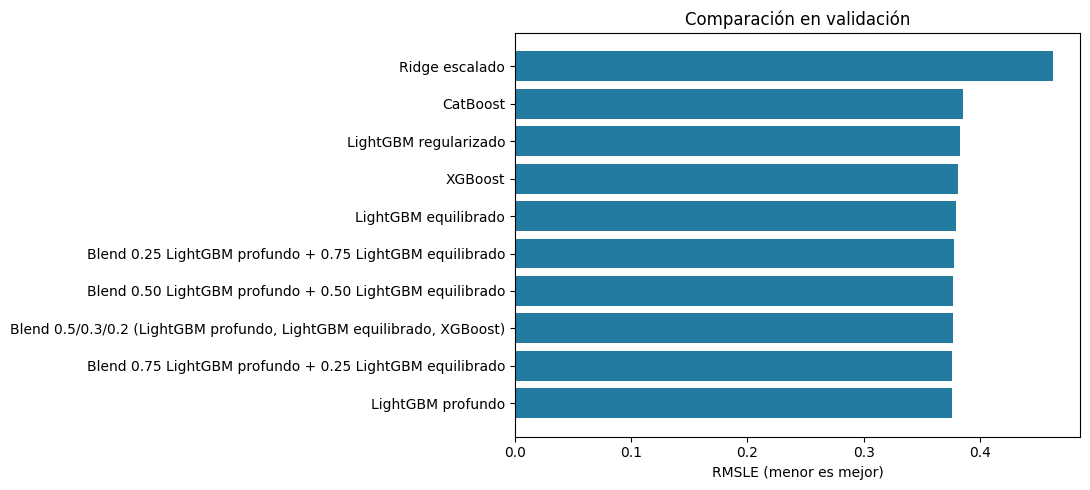

In [13]:
comparison=pd.DataFrame(records).sort_values('RMSLE').reset_index(drop=True)
display(comparison.style.format({'RMSLE':'{:.6f}','MAE_segundos':'{:.2f}','RMSE_segundos':'{:.2f}','R2':'{:.4f}','MAPE_%':'{:.2f}'}))
comparison.to_csv(ARTIFACTS/'comparacion_modelos.csv',index=False)
base_candidates=comparison.loc[comparison.Modelo.isin(['LightGBM equilibrado','LightGBM profundo','LightGBM regularizado','XGBoost','CatBoost']),'Modelo'].tolist()
blend_proposals=[]
if len(base_candidates)>=2:
    a,b=base_candidates[:2]
    for w in [.25,.50,.75]:
        pred=seconds_from_log(w*np.log1p(valid_predictions[a])+(1-w)*np.log1p(valid_predictions[b]))
        blend_proposals.append((f'Blend {w:.2f} {a} + {1-w:.2f} {b}',pred,[(a,w),(b,1-w)]))
if len(base_candidates)>=3:
    a,b,c=base_candidates[:3]
    pred=seconds_from_log(.5*np.log1p(valid_predictions[a])+.3*np.log1p(valid_predictions[b])+.2*np.log1p(valid_predictions[c]))
    blend_proposals.append((f'Blend 0.5/0.3/0.2 ({a}, {b}, {c})',pred,[(a,.5),(b,.3),(c,.2)]))
for name,pred,desc in blend_proposals: record(name,pred)
comparison=pd.DataFrame(records).sort_values('RMSLE').reset_index(drop=True)
comparison.to_csv(ARTIFACTS/'comparacion_modelos.csv',index=False)
selected_name=str(comparison.iloc[0].Modelo)
blend_lookup={name:weights for name,pr,weights in blend_proposals}
selected_components=blend_lookup.get(selected_name,[(selected_name,1.0)])
print('SELECCIONADO:',selected_name,'| RMSLE de validación:',round(float(comparison.iloc[0].RMSLE),6))
print('Componentes:',selected_components)
display(comparison.head(10))
fig,ax=plt.subplots(figsize=(11,5)); top=comparison.head(10).sort_values('RMSLE')
ax.barh(top.Modelo,top.RMSLE,color='#247ba0');ax.set_xlabel('RMSLE (menor es mejor)');ax.set_title('Comparación en validación');plt.tight_layout()
plt.savefig(GRAPHS/'02_comparacion_modelos.png',dpi=150,bbox_inches='tight');plt.show()

## 8. Evaluación FINAL en holdout inédito
Solo ahora aplicamos el modelo seleccionado a las **70,000 observaciones reservadas**. En este subconjunto no elegimos parámetros ni repetimos hasta lograr un resultado atractivo; por eso constituye una estimación más honesta de generalización. Se presentan RMSLE y métricas complementarias.

In [14]:
def ensemble_predict(fitted,weights,X):
    weighted=np.zeros(len(X),dtype=np.float64)
    for name,w in weights:
        m=fitted[name]
        z=m.predict(X)
        weighted+=w*np.maximum(z,0)
    return seconds_from_log(weighted)
ph=ensemble_predict(trained,selected_components,Xho)
holdout_stats=regression_metrics(yho,ph)
validation_stats=regression_metrics(yva,valid_predictions[selected_name])
print('Métrica oficial (menor es mejor):')
print('    RMSLE validación:',round(validation_stats['RMSLE'],6))
print('    RMSLE holdout   :',round(holdout_stats['RMSLE'],6))
display(pd.DataFrame([{'Conjunto':'Validación',**validation_stats},{'Conjunto':'Holdout',**holdout_stats}]).set_index('Conjunto'))
with open(ARTIFACTS/'metricas.json','w',encoding='utf-8') as f:
    json.dump({'modelo_seleccionado':selected_name,'componentes':selected_components,
               'validacion':validation_stats,'holdout':holdout_stats,'parametros_candidatos':params_used,
               'semilla':SEED,'observaciones_train':int(len(tr_fit)),
               'observaciones_validacion':int(len(va)), 'observaciones_holdout':int(len(ho))},f,ensure_ascii=False,indent=2)

/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


Métrica oficial (menor es mejor):
    RMSLE validación: 0.375735
    RMSLE holdout   : 0.381219


,RMSLE,MAE_segundos,RMSE_segundos,R2,MAPE_%
Conjunto,,,,,
Validación,0.375735,282.328282,3220.921653,0.033753,24.735160
Holdout,0.381219,270.915359,3062.549679,0.038994,25.475825


## 9. Diagnóstico de errores, sesgo y variables relevantes
Se examina el error en log para que los viajes excepcionalmente largos no oculten patrones. El gráfico de predicho vs. real en escala logarítmica permite detectar sistemáticamente subestimaciones. También revisamos el rendimiento por distancia para detectar limitaciones. La importancia de variables de árboles es **descriptiva**, no inferencia causal.

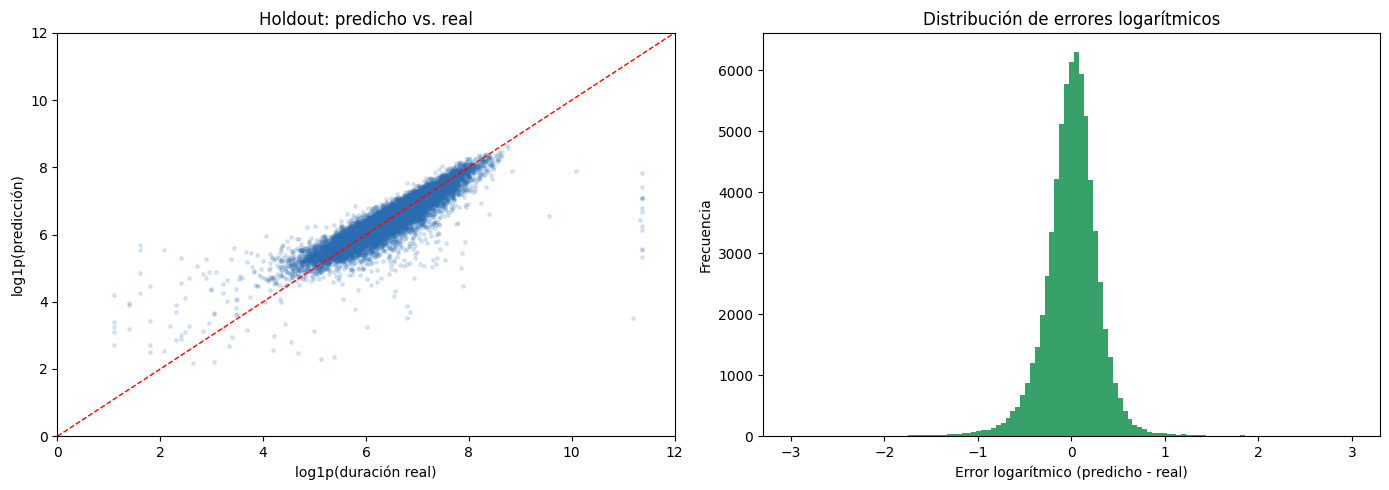

,Distancia,n,RMSLE
0,<0.5 km,2504,1.103559
1,0.5–2 km,31070,0.368468
2,2–5 km,23896,0.290010
3,5–10 km,8250,0.260631
4,10–25 km,4200,0.275810
5,>25 km,76,0.245508


,variable,importancia
53,pickup_dist_jfk_km,7057
16,hour_cos,6811
15,hour_sin,6436
6,day_of_year,5505
68,dropoff_dist_jfk_km,5421
78,hour_x_distance,5193
33,haversine_km,5166
10,hour_decimal,4983
5,day,4354
31,abs_dx_km,4279


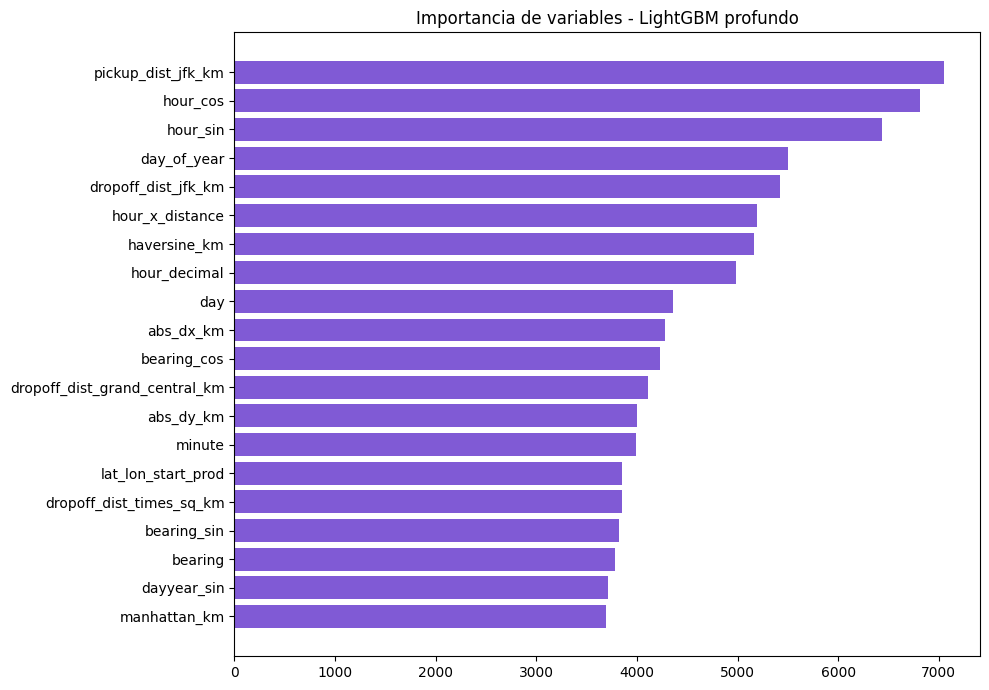

In [15]:
fig,axs=plt.subplots(1,2,figsize=(14,5))
rng=np.random.default_rng(SEED)
idx=rng.choice(len(yho),size=min(13000,len(yho)),replace=False)
axs[0].scatter(np.log1p(yho[idx]),np.log1p(ph[idx]),alpha=.15,s=6,color='#2b6cb0')
axs[0].plot([0,12],[0,12],'r--',lw=1);axs[0].set(xlim=(0,12),ylim=(0,12),xlabel='log1p(duración real)',ylabel='log1p(predicción)',title='Holdout: predicho vs. real')
errs=np.log1p(ph)-np.log1p(yho)
axs[1].hist(errs,bins=115,range=(-3,3),color='#38a169');axs[1].set(xlabel='Error logarítmico (predicho - real)',ylabel='Frecuencia',title='Distribución de errores logarítmicos')
plt.tight_layout();plt.savefig(GRAPHS/'03_diagnostico_holdout.png',dpi=145,bbox_inches='tight');plt.show()
distance_bins=pd.cut(Xho_raw['haversine_km'],bins=[-np.inf,.5,2,5,10,25,np.inf],labels=['<0.5 km','0.5–2 km','2–5 km','5–10 km','10–25 km','>25 km'])
group_stats=[]
for name in distance_bins.cat.categories:
    subset=(distance_bins==name).to_numpy()
    if subset.sum()>0: group_stats.append({'Distancia':name,'n':int(subset.sum()),'RMSLE':rmsle(yho[subset],ph[subset])})
seg=pd.DataFrame(group_stats)
display(seg);seg.to_csv(ARTIFACTS/'error_por_distancia.csv',index=False)
if any(name.startswith('LightGBM') for name,w in selected_components):
    key=next(name for name,w in selected_components if name.startswith('LightGBM'))
    imp=trained[key].feature_importances_
    impdf=pd.DataFrame({'variable':COLUMNS,'importancia':imp}).sort_values('importancia',ascending=False)
    display(impdf.head(20)); impdf.to_csv(ARTIFACTS/'importancia_variables.csv',index=False)
    fig,ax=plt.subplots(figsize=(10,7)); imp_top=impdf.head(20).iloc[::-1];ax.barh(imp_top.variable,imp_top.importancia,color='#805ad5')
    ax.set_title('Importancia de variables - '+key);plt.tight_layout();plt.savefig(GRAPHS/'04_importancia_variables.png',dpi=150,bbox_inches='tight');plt.show()
else:
    if 'XGBoost' in trained:
        impdf=pd.DataFrame({'variable':COLUMNS,'importancia':trained['XGBoost'].feature_importances_}).sort_values('importancia',ascending=False)
        impdf.to_csv(ARTIFACTS/'importancia_variables.csv',index=False);display(impdf.head(20))

## 10. Reentrenamiento final con TODOS los datos etiquetados utilizables
Después de comparar y medir holdout, ya podemos incorporar esos datos al ajuste final. Volvemos a aplicar la misma regla sobre anomalías del **objetivo solo en entrenamiento**; recalculamos las medianas usando el train completo (nunca el test ciego). Se reajusta cada componente del modelo ganador usando el número de árboles estimado en validación. **No se reajusta con `test.csv` ni con ninguna duración desconocida**.

In [16]:
full_train=train.loc[train[TARGET].between(1,MAX_TRAIN_TARGET)].copy()
Xfull_raw=create_features(full_train)
final_imputer=SimpleImputer(strategy='median',keep_empty_features=True)
Xfull=final_imputer.fit_transform(Xfull_raw[COLUMNS]).astype(np.float32)
zfull=np.log1p(full_train[TARGET].to_numpy(dtype=np.float64))
final_models={}
for name,weight in selected_components:
    start=time.time()
    if name.startswith('LightGBM'):
        p={k:v for k,v in params_used[name].items() if k!='best_iteration_'}
        p['n_estimators']=max(50,int(params_used[name]['best_iteration_']))
        m=LGBMRegressor(**p,objective='regression',random_state=SEED,n_jobs=6,verbosity=-1)
        m.fit(Xfull,zfull,feature_name=COLUMNS)
    elif name=='XGBoost':
        p=params_used['XGBoost']
        m=XGBRegressor(n_estimators=max(50,p['best_iteration']+1),learning_rate=p['learning_rate'],
                       max_depth=p['max_depth'],min_child_weight=p['min_child_weight'],subsample=p['subsample'],
                       colsample_bytree=p['colsample_bytree'],reg_lambda=p['reg_lambda'],tree_method='hist',
                       objective='reg:squarederror',n_jobs=6,random_state=SEED)
        m.fit(Xfull,zfull,verbose=False)
    elif name=='CatBoost':
        p=params_used['CatBoost']
        m=CatBoostRegressor(iterations=max(50,p['best_iteration']+1),depth=p['depth'],learning_rate=p['learning_rate'],
                            l2_leaf_reg=p['l2_leaf_reg'],loss_function='RMSE',random_seed=SEED,thread_count=6,verbose=False)
        m.fit(Xfull,zfull,verbose=False)
    elif name=='Ridge escalado':
        m=Pipeline([('scaler',RobustScaler()),('regresion',Ridge(alpha=100.0))]);m.fit(Xfull,zfull)
    else:
        m=DummyRegressor(strategy='median').fit(Xfull,zfull)
    final_models[name]=m
    print('Reentrenado:',name,'| peso:',weight,'| segundos:',round(time.time()-start,1))
model_bundle={'modelos':final_models,'componentes':selected_components,
              'imputer':final_imputer,'columnas':COLUMNS,'max_train_duration':MAX_TRAIN_TARGET,
              'semilla':SEED,'rmsle_validacion':validation_stats['RMSLE'],
              'rmsle_holdout':holdout_stats['RMSLE']}
joblib.dump(model_bundle,MODELS/'modelo_final.joblib',compress=3)
print('Archivo de modelo:',(MODELS/'modelo_final.joblib').stat().st_size//1024,'KB')

Reentrenado: LightGBM profundo | peso: 1.0 | segundos: 141.2


Archivo de modelo: 6172 KB


## 11. Predicción de 100,000 viajes ciegos y CSV obligatorio
Se realiza `transform()` (sin `fit`) sobre los viajes de prueba. Validaciones automáticas de **columnas exactas**, cantidad de filas, IDs únicos, orden preservado, valores numéricos finitos y predicción no negativa. La duración debe entregarse en segundos, no en log-segundos.

In [17]:
Xtest_raw=create_features(test)
Xtest=final_imputer.transform(Xtest_raw[COLUMNS]).astype(np.float32)
ptest=ensemble_predict(final_models,selected_components,Xtest)
submission=pd.DataFrame({'id':original_test_ids.to_numpy(),'trip_duration':ptest})
assert submission.columns.tolist()==['id','trip_duration']
assert len(submission)==len(test)==100_000
assert submission['id'].is_unique
assert (submission.id.to_numpy()==original_test_ids.to_numpy()).all()
assert np.isfinite(submission.trip_duration.to_numpy()).all()
assert (submission.trip_duration>=0).all()
assert submission.trip_duration.dtype.kind in 'fi'
submission.to_csv(ROOT/'submission.csv',index=False,float_format='%.5f')
# comprobación de ida/vuelta para asegurar que el archivo en disco cumple.
check=pd.read_csv(ROOT/'submission.csv')
assert list(check.columns)==['id','trip_duration'] and len(check)==len(test)
assert check.id.equals(test.id) and check.id.is_unique
assert check.trip_duration.ge(0).all() and np.isfinite(check.trip_duration).all()
print('CSV VALIDADO:',(ROOT/'submission.csv').resolve())
print('Predicciones mín/máx/mediana:',submission.trip_duration.min(),submission.trip_duration.max(),submission.trip_duration.median())
display(submission.head(8))

/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


CSV VALIDADO: /mnt/data/submission.csv
Predicciones mín/máx/mediana: 1.2995217331076643 5762.077834713864 650.794534003421


,id,trip_duration
0,036771038fbe404fabdf699955443500,722.292249
1,2ea1c0ddab68440e9a6183ee6e32aeef,761.440260
2,eb2d997eea384112bd74146b48b461dd,391.229140
3,c104ede33a344de0bf1d7ced9cbb9c7c,404.069120
4,fd4d0e3c804a4c9f97cebfac386f7ed4,929.164730
5,efd618d97bc243188fa2f2adf35a237a,419.134372
6,92da0224ebb346e89ba1a33acfa12f15,1149.549865
7,43d6b8ab322443908708eabb7b8a40d2,595.917952


## 12. Informe, reproducibilidad y conclusiones
El notebook entrega el archivo `submission.csv`, un modelo serializado, comparaciones y gráficos. **No es posible conocer el RMSLE real de `test.csv` porque carece de etiquetas**. El RMSLE de holdout es solo una estimación, no una garantía de obtener el mismo puntaje en la evaluación ciega.

La selección de mejores hiperparámetros se limita a los ensayos documentados: no se debe afirmar que sea el óptimo global. Un siguiente ciclo de CRISP-DM podría incluir rutas reales (sin fuga), tráfico externo disponible en tiempo de predicción, agrupamiento geográfico y validación adicional para robustez temporal.

In [18]:
selected_report=f'''# Informe final: duración de viajes de taxi NYC

## Problema
Predicción supervisada de tiempo de viaje (segundos), evaluada por RMSLE.

## Datos
- Train: {len(train):,} viajes.
- Test ciego: {len(test):,} viajes.
- Entrenamiento usado en selección tras filtrar duraciones >12h: {len(tr_fit):,}.
- Validación: {len(va):,}; holdout: {len(ho):,}.
- Variables derivadas: {len(COLUMNS)}.
- Observaciones con duración >12h en train completo: {int((train.trip_duration>MAX_TRAIN_TARGET).sum()):,}.

## Resultado de experimentos
- Modelo ganador en validación: **{selected_name}**.
- **RMSLE validación: {validation_stats['RMSLE']:.6f}**.
- **RMSLE holdout final: {holdout_stats['RMSLE']:.6f}**.
- MAE holdout: {holdout_stats['MAE_segundos']:.2f} segundos.
- RMSE holdout: {holdout_stats['RMSE_segundos']:.2f} segundos.
- R² holdout: {holdout_stats['R2']:.5f}.
- MAPE holdout: {holdout_stats['MAPE_%']:.2f}% (inestable cerca de cero).

## Entrega
- `submission.csv`: **{len(submission):,}** filas, exactamente `id,trip_duration`.
- `modelos/modelo_final.joblib`: modelo ajustado en train completo.
- `resultados/comparacion_modelos.csv`, `resultados/metricas.json`, `resultados/auditoria_calidad.json` y gráficos.

## Interpretación
RMSLE es la función de evaluación oficial: menor es mejor. F1, accuracy, precision y recall requieren clases y no son indicadores válidos para predecir valores continuos. Test ciego no permite calcular resultados contra la verdad hasta que se proporcionen sus etiquetas. El holdout jamás se usó para elegir el modelo.

## Fuentes docentes
- **U5 - 01 - ML.pdf:** clasificación vs. regresión (pág. 7).
- **U5 - 02 - Perceptrón.pdf:** regresión lineal y función de costo (págs. 3–7).
- **03 - Ciclo de vida del ML.pdf:** CRISP-DM, auditoría, partición, imputación, escalado, fuga de datos y métricas (págs. 2–5 y 8–25).
'''
(ARTIFACTS/'informe_resultados.md').write_text(selected_report,encoding='utf-8')
print(selected_report)
print('✅ Trabajo completado: entrega lista.')

# Informe final: duración de viajes de taxi NYC

## Problema
Predicción supervisada de tiempo de viaje (segundos), evaluada por RMSLE.

## Datos
- Train: 700,000 viajes.
- Test ciego: 100,000 viajes.
- Entrenamiento usado en selección tras filtrar duraciones >12h: 559,212.
- Validación: 70,000; holdout: 70,000.
- Variables derivadas: 81.
- Observaciones con duración >12h en train completo: 984.

## Resultado de experimentos
- Modelo ganador en validación: **LightGBM profundo**.
- **RMSLE validación: 0.375735**.
- **RMSLE holdout final: 0.381219**.
- MAE holdout: 270.92 segundos.
- RMSE holdout: 3062.55 segundos.
- R² holdout: 0.03899.
- MAPE holdout: 25.48% (inestable cerca de cero).

## Entrega
- `submission.csv`: **100,000** filas, exactamente `id,trip_duration`.
- `modelos/modelo_final.joblib`: modelo ajustado en train completo.
- `resultados/comparacion_modelos.csv`, `resultados/metricas.json`, `resultados/auditoria_calidad.json` y gráficos.

## Interpretación
RMSLE es la función d